In [1]:
# Legacy diagnostics use a separate namespace so they cannot overwrite
# the current simulation's 2-D theory arrays used by Eqs. (74) and (75).
def run_legacy_simulation():
    import numpy as np
    import matplotlib.pyplot as plt
    dsep = 0.5  # Antenna separation in wavelengths
    snr0_dB = 10  # Initial SNR0 in dB
    snr1_dB = 10  # Initial SNR1 in dB
    sigma_N0 = 10**(-0.1 * snr0_dB)
    sigma_N1 = 10**(-0.1 * snr1_dB)

    nsamp = 100  # Number of samples
    t = np.arange(nsamp)
    X = np.exp(1j * 2 * np.pi * 0.1*t).reshape(-1, 1) # reference signal
    E_r = np.linalg.norm(X)**2
    E_t = np.linalg.norm(X)**2/nsamp

    theta0 = 0  # Angle to RX0
    theta1 = 15
    theta0_rad = theta0 * np.pi / 180
    theta1_rad = theta1 * np.pi / 180
    num = 1

    ntx_num = np.array([  16*num,32*num,48*num,64*num])
    ntx_len = len(ntx_num)
    nt = 50 # tota; runing times
    gamma_num = 500
    gamma_h1 = np.logspace(-4, 8, gamma_num) # adjustment to h1



    inr = np.zeros((ntx_len,nt,gamma_num  ))
    G_i = np.zeros((ntx_len,nt,gamma_num  ))
    INR_theory_correct = np.zeros((ntx_len,nt,gamma_num  ))
    INR_theory_incorrect = np.zeros((ntx_len,nt,gamma_num  ))
    INR_new = np.zeros((ntx_len,nt,gamma_num  ))
    INR_pow= np.zeros((ntx_len,nt,gamma_num  ))
    INR0_pow= np.zeros((ntx_len,nt,gamma_num  ))
    INR2_pow= np.zeros((ntx_len,nt,gamma_num  ))
    INR3_pow= np.zeros((ntx_len,nt,gamma_num  ))
    INR4_pow= np.zeros((ntx_len,nt,gamma_num  ))
    INR5_pow= np.zeros((ntx_len,nt,gamma_num  ))

    S0_list =np.zeros((ntx_len,nt,gamma_num  ))
    D0_list  = np.zeros((ntx_len,nt,gamma_num  ))
    V0_list = np.zeros((ntx_len,nt,gamma_num  ))
    rho_hat_list = np.zeros((ntx_len,nt,gamma_num  ))
    rho_nom_abs2_list= np.zeros((ntx_len,nt,gamma_num  ))


    def beamforming_vec(h0, h1):

        C0 = np.linalg.norm(h0)**2
        C1 = np.linalg.norm(h1)**2
        # rho = np.conj(h0.T) @ h1 / np.sqrt(C1 * C0)
        rho = ((np.conj(h1.T) @ h0) / np.sqrt(C1 * C0)).item()
        alpha0 = 1 / (np.sqrt(1 - np.abs(rho)**2) * np.sqrt(C0))
        alpha1 = -rho / (np.sqrt(1 - np.abs(rho)**2) * np.sqrt(C1))
        w = alpha0 * h0 + alpha1 * h1

        return w, rho

    for ntxn, ntx in enumerate(ntx_num):

        phase0 = 2 * np.pi * np.arange(ntx) * dsep * np.cos(theta0_rad)
        phase1 = 2 * np.pi * np.arange(ntx) * dsep * np.cos(theta1_rad)
        h0 = np.exp(1j * phase0).reshape(-1,1)
        h1 = np.exp(1j * phase1).reshape(-1,1)

        for g, gamma in enumerate(gamma_h1):


            for n in range (nt):

                G_i[ntxn,n,g] = np.linalg.norm(gamma*h1)**2  /ntx
                G_0 = np.linalg.norm(h0)**2  /ntx
                             # gamma_r^i in paper
                N = (np.random.randn(ntx, nsamp) + 1j * np.random.randn(ntx, nsamp)) * np.sqrt(sigma_N1 / 2)  #
                N0 = np.mean(np.abs(N)**2)
                # N0_total = np.abs(N)**2
                snr_1_r = E_r*G_i[ntxn,n,g]/N0
            
            
                Y_i = gamma*h1 @ X.reshape(1, nsamp) + N  #
                # h1_est = np.sum(Y_i * (np.conj(X) / (np.abs(X) ** 2)), axis=1) / nsamp.reshape(-1,1)
                # h1_est = np.sum(Y_i * (np.conj(X) / (np.abs(X) ** 2)), axis=1) / nsamp
                # h1_hat = ((h1_est)*np.sqrt(ntx)  /np.linalg.norm(h1_est)).reshape(-1,1) # normalized h1_est to sqrt|ntx|
            
            
                h1_est = Y_i @ np.conj(X) / E_r
                h1_hat  = h1_est
            
            
                V = h1_hat - gamma*h1

                [w_t,rho_hat] = beamforming_vec(h0, h1_hat)
            
            
            

            
            
                h1_ = ((gamma*h1)*np.sqrt(ntx)  /np.linalg.norm(gamma*h1)).reshape(-1,1) # real h1 after normalized to sqrt|ntx|
                [w_real,rho] = beamforming_vec(h0, h1_)  # real rho
            
            
                rho_nom_abs2 = np.abs(rho)**2   
                rho_hat_nom_abs2 = np.abs(rho_hat)**2 
            
                rho_hat_list[ntxn,n,g] = np.linalg.norm(rho_hat)**2
                rho_nom_abs2_list[ntxn,n,g] = np.linalg.norm(rho)**2
            
                # the real inr
                inr[ntxn,n,g] = np.abs((np.conj(w_t.T) @ (gamma*h1)).item())**2 / N0    
            
                 
                # the inr with 1-rho in equ(21), which matches the real inr
                INR_theory_incorrect[ntxn,n,g] = (E_t/E_r) * (snr_1_r / ((1+snr_1_r)*(1+snr_1_r - snr_1_r * rho_nom_abs2))) * \
                                 (rho_nom_abs2 * ntx + snr_1_r * (1 - rho_nom_abs2))
                             
                # the inr with 1+rho in equ(20), which matches the formula                 
                INR_theory_correct[ntxn,n,g] = (E_t/E_r) * (snr_1_r / ((1+snr_1_r)*(1+snr_1_r - snr_1_r * rho_nom_abs2))) * \
                                 (rho_nom_abs2 * ntx + snr_1_r * (1 + rho_nom_abs2))
                             
                             
                INR_new[ntxn,n,g] = (E_t/E_r) * (snr_1_r / ((1+snr_1_r)*(1+snr_1_r - snr_1_r * rho_nom_abs2))) * \
                                        (rho_nom_abs2 * ntx + (1 + rho_nom_abs2)/snr_1_r )
                             
                # the inr from S(D^2+E(V)^2),as equ (54-a)                  
                S = (1+snr_1_r)/ntx/G_0/(1+snr_1_r-snr_1_r*rho_nom_abs2)            
                D_pow = ntx**2 * rho_nom_abs2 *G_i[ntxn,n,g] *G_0 / (1+snr_1_r)**2            
                V_pow = N0* (snr_1_r**2)*ntx*G_0*(1+rho_nom_abs2)/E_r/((1+snr_1_r)**2)
            
                INR_pow[ntxn,n,g] = E_t/N0*S*(D_pow+V_pow)
            
                S0 = 1/(np.linalg.norm(h0)**2*(1-rho_hat_nom_abs2))
                D0 = np.conj(h0.T)@h1*(1-np.linalg.norm(h1)**2/np.linalg.norm(h1_hat)**2)- (np.conj(h0.T)@V@np.conj(V.T)@h1)/(np.linalg.norm(h1_hat)**2)
                V0 = (np.conj(h0.T)@V*np.linalg.norm(h1)**2+np.conj(h0.T)@h1@np.conj(V.T)@h1)/(np.linalg.norm(h1_hat)**2)
                INR0_pow[ntxn,n,g] = E_t/N0*S0*(D_pow+V_pow)                    
                INR4_pow[ntxn,n,g] = E_t/N0*S0*(np.linalg.norm(D0-V0)**2)
                INR5_pow[ntxn,n,g] = E_t/N0*S0*(np.linalg.norm(D0)**2+np.linalg.norm(V0)**2)
            
                Eh1hat2 = np.linalg.norm(gamma*h1)**2 + ntx * N0 / E_r
                D_pow2 = np.abs((np.conj(h0.T) @ (gamma*h1)).item())**2 * \
                        np.abs(1 - (np.linalg.norm(gamma*h1)**2 + N0/E_r) / Eh1hat2 )**2
                    
                V_a = (np.conj(h0.T) @ V) * (np.linalg.norm(h1)**2)
                h1H_h0 = np.conj(h1.T) @ h0   # (1,1) ≈ h1^H h0
                h1H_v1 = np.conj(h1.T) @ V   # (1,1) ≈ h1^H v1
                V_b = h1H_h0 * h1H_v1
                V_b_conj = np.conj(V_b) 
                V02 = (V_a + np.conj(V_b)) / Eh1hat2
            
            
                INR2_pow[ntxn,n,g] = E_t/N0*S*(D_pow2+V_pow)
                INR3_pow[ntxn,n,g] = E_t/N0*S0*(D_pow+np.linalg.norm(V02 )**2)
            
            
            # Monte Carlo 平均

    return {
        "ntx_num": ntx_num,
        "G_i": G_i,
        "inr": inr,
        "INR_theory_correct": INR_theory_correct,
        "INR_theory_incorrect": INR_theory_incorrect,
        "INR_new": INR_new,
        "INR_pow": INR_pow,
        "INR0_pow": INR0_pow,
        "INR2_pow": INR2_pow,
        "INR3_pow": INR3_pow,
        "INR4_pow": INR4_pow,
        "INR5_pow": INR5_pow,
        "rho_hat_list": rho_hat_list,
        "rho_nom_abs2_list": rho_nom_abs2_list,
    }

legacy_results = run_legacy_simulation()


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- System setup ----------
dsep = 0.5
snr0_dB = 10
snr1_dB = 10
sigma_N0 = 10**(-0.1 * snr0_dB)
sigma_N1 = sigma_N0

nsamp = 100
t = np.arange(nsamp)
X = np.exp(1j * 2 * np.pi * 0.1 * t).reshape(-1, 1)
E_r = np.linalg.norm(X)**2
E_t = np.linalg.norm(X)**2 / nsamp

theta0 = 0
theta1 = 15
theta0_rad = theta0 * np.pi / 180
theta1_rad = theta1 * np.pi / 180

ntx_num = np.array([16, 32, 48, 64])
ntx_len = len(ntx_num)
nt = 50
gamma_num = 500
gamma_h1 = np.logspace(-4, 8, gamma_num)

# ---------- Storage ----------
inr = np.zeros((ntx_len, nt, gamma_num))
G_i = np.zeros((ntx_len, gamma_num))
INR_theory_correct = np.zeros((ntx_len, gamma_num))
INR_theory_incorrect = np.zeros((ntx_len, gamma_num))
INR_from_SDV = np.zeros((ntx_len, gamma_num))


INR4_pow = np.zeros((ntx_len, gamma_num))  # S0 (|D0|^2 + E|V|^2)
INR5_pow = np.zeros((ntx_len, gamma_num))  # optional: S0 E|D0 - V|^2 (if you want to see it)

rho_hat_list = np.zeros((ntx_len, nt, gamma_num))
rho_nom_abs2 = np.zeros(ntx_len)

# ---------- Beamformer ----------
def beamforming_vec(h0, h1):
    C0 = np.linalg.norm(h0)**2
    C1 = np.linalg.norm(h1)**2
    rho = ((h1.conj().T @ h0) / np.sqrt(C1 * C0)).item()
    alpha0 = 1 / (np.sqrt(1 - np.abs(rho)**2) * np.sqrt(C0))
    alpha1 = -rho / (np.sqrt(1 - np.abs(rho)**2) * np.sqrt(C1))
    w = alpha0 * h0 + alpha1 * h1
    return w, rho

# ---------- Main simulation ----------
for ntxn, ntx in enumerate(ntx_num):

    phase0 = 2 * np.pi * np.arange(ntx) * dsep * np.cos(theta0_rad)
    phase1 = 2 * np.pi * np.arange(ntx) * dsep * np.cos(theta1_rad)
    h0 = np.exp(1j * phase0).reshape(-1, 1)
    h1 = np.exp(1j * phase1).reshape(-1, 1)

    G0 = np.linalg.norm(h0)**2 / ntx
    _, rho_true = beamforming_vec(h0, h1 / np.linalg.norm(h1) * np.sqrt(ntx))
    rho_nom_abs2[ntxn] = np.abs(rho_true)**2

    for g, gamma in enumerate(gamma_h1):

        h1_scaled = gamma * h1
        G1 = np.linalg.norm(h1_scaled)**2 / ntx
        G_i[ntxn, g] = G1

        gamma_r = E_r * G1 / sigma_N1
        rho2 = rho_nom_abs2[ntxn]

        S_th = (1 + gamma_r) / (ntx * G0 * (1 + gamma_r - gamma_r * rho2))
        D_pow_th = ntx**2 * rho2 * G0 * G1 / (1 + gamma_r)**2
        V_pow_th = sigma_N1 * (gamma_r**2) * ntx * G0 * (1 + rho2) / (E_r * (1 + gamma_r)**2)

        INR_from_SDV[ntxn, g] = (E_t / sigma_N1) * S_th * (D_pow_th + V_pow_th)

        INR_theory_correct[ntxn, g] = (
            (E_t / E_r) * gamma_r /
            ((1 + gamma_r) * (1 + gamma_r - gamma_r * rho2)) *
            (rho2 * ntx + gamma_r * (1 + rho2))
        )

        INR_theory_incorrect[ntxn, g] = (
            (E_t / E_r) * gamma_r /
            ((1 + gamma_r) * (1 + gamma_r - gamma_r * rho2)) *
            (rho2 * ntx + gamma_r * (1 - rho2))
        )
        
        sum_h1hat2 = 0.0          # E||h1_hat||^2
        sum_rhohat2 = 0.0         # E|rho_hat|^2
        sum_h0v1v1h1 = 0+0j       # E[h0^H v1 v1^H h1]
        sum_Vnum2 = 0.0           # E|num_V|^2, where V ≈ num_V / E||h1_hat||^2
        num_V_samples = np.zeros(nt, dtype=np.complex128)

        for n in range(nt):

            N = (np.random.randn(ntx, nsamp) +
                 1j * np.random.randn(ntx, nsamp)) * np.sqrt(sigma_N1 / 2)

            Y_i = h1_scaled @ X.T + N
            h1_hat = (Y_i @ np.conj(X)) / E_r

            w_t, rho_hat = beamforming_vec(h0, h1_hat)
            rho_hat_list[ntxn, n, g] = np.abs(rho_hat)**2

            inr[ntxn, n, g] = (
                np.abs((w_t.conj().T @ h1_scaled).item())**2 / sigma_N1 * E_t
            )
                        # v1 = channel estimation error on h1_scaled
            v1 = h1_hat - h1_scaled

            # accumulate expectations
            sum_h1hat2 += np.linalg.norm(h1_hat)**2
            sum_rhohat2 += np.abs(rho_hat)**2
            sum_h0v1v1h1 += (h0.conj().T @ v1) * (v1.conj().T @ h1_scaled)

            # numerator of V in (Vdef) with E||h1_hat||^2 in the denominator
            num_V = (h0.conj().T @ v1) * np.linalg.norm(h1_scaled)**2 + \
                    (h0.conj().T @ h1_scaled) * (v1.conj().T @ h1_scaled)
            sum_Vnum2 += np.abs(num_V)**2
            
                        # numerator of V(ω) from Vdef:
            # V = [ h0^H v1 ||h1||^2 + h0^H h1 v1^H h1 ] / E||ĥ1||^2
            h0H_v1 = h0.conj().T @ v1           # (1,1)
            h0H_h1 = h0.conj().T @ h1_scaled    # (1,1)
            h1H_v1 = h1_scaled.conj().T @ v1    # (1,1)
            num_V = h0H_v1 * (np.linalg.norm(h1_scaled)**2) + \
                    h0H_h1 * h1H_v1
            num_V_samples[n] = num_V.squeeze()

        # ---- turn MC sums into expectations ----
        Eh1hat2  = sum_h1hat2 / nt
        Erhohat2 = sum_rhohat2 / nt
        Eh0v1v1h1 = sum_h0v1v1h1 / nt

        # S0 in (Sdef) with E|rho_hat|^2
        S0 = 1.0 / (np.linalg.norm(h0)**2 * (1.0 - Erhohat2.real))

        # D0 as in (Ddef) with expectations
        D0 = (h0.conj().T @ h1_scaled) * \
             (1.0 - np.linalg.norm(h1_scaled)**2 / Eh1hat2) - \
             Eh0v1v1h1 / Eh1hat2

        # E|V|^2: (num_V / Eh1hat2)^2 averaged over MC
        EV2 = (sum_Vnum2 / nt) / (Eh1hat2**2)
        V_samples = num_V_samples / Eh1hat2
        EV2 = np.mean(np.abs(V_samples)**2)
        
        # INR ≈ (E_t/N0) S0 (|D|^2 + E|V|^2)
        INR4_pow[ntxn, g] = (E_t / sigma_N1) * S0 * (np.abs(D0.item())**2 + EV2)

        # optional: E|D - V|^2 if you want to see the "wrong" structure
        # here we approximate E[(D - V)(D - V)^*] ≈ |D0|^2 + EV2 (cross term ~0),
        # so INR5_pow will be almost the same as INR4_pow
        E_DminusV2 = np.mean(np.abs(D0 - V_samples)**2)
        INR5_pow[ntxn, g] = (E_t / sigma_N1) * S0 * E_DminusV2

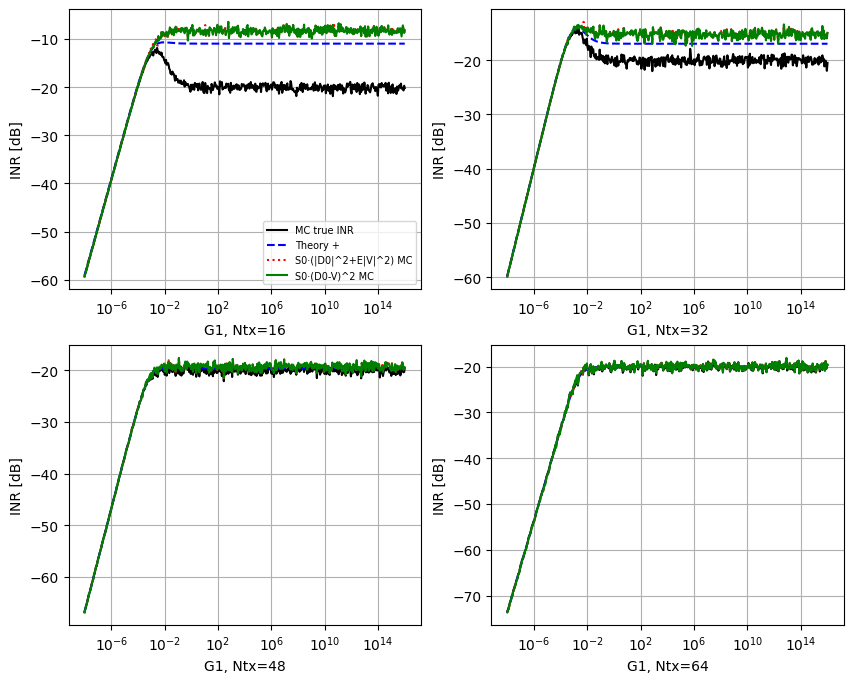

In [3]:
plt.figure(figsize=(10, 8))

for idx, ntx in enumerate(ntx_num):

    mean_G_i       = G_i[idx, :]
    mean_INR_sim   = 10*np.log10(np.mean(inr[idx, :, :], axis=0))
    mean_INR_corr  = 10*np.log10(INR_theory_correct[idx, :])
    mean_INR_SDV   = 10*np.log10(INR_from_SDV[idx, :])
    mean_INR_D2V2 = 10*np.log10(INR4_pow[idx, :])
    mean_INR_DV = 10*np.log10(INR5_pow[idx, :])

    plt.subplot(2, 2, idx + 1)
    plt.semilogx(mean_G_i, mean_INR_sim,   'k',  label='MC true INR')
    plt.semilogx(mean_G_i, mean_INR_corr,  'b--', label='Theory +')
    # plt.semilogx(mean_G_i, mean_INR_SDV,   'g-.', label='Theory -')
    plt.semilogx(mean_G_i, mean_INR_D2V2, 'r:', label='S0·(|D0|^2+E|V|^2) MC')
    plt.semilogx(mean_G_i, mean_INR_DV , 'g-', label='S0·(D0-V)^2 MC')

    plt.xlabel(f'G1, Ntx={ntx}')
    plt.ylabel('INR [dB]')
    plt.grid(True)
    if idx == 0:
        plt.legend(fontsize=7)


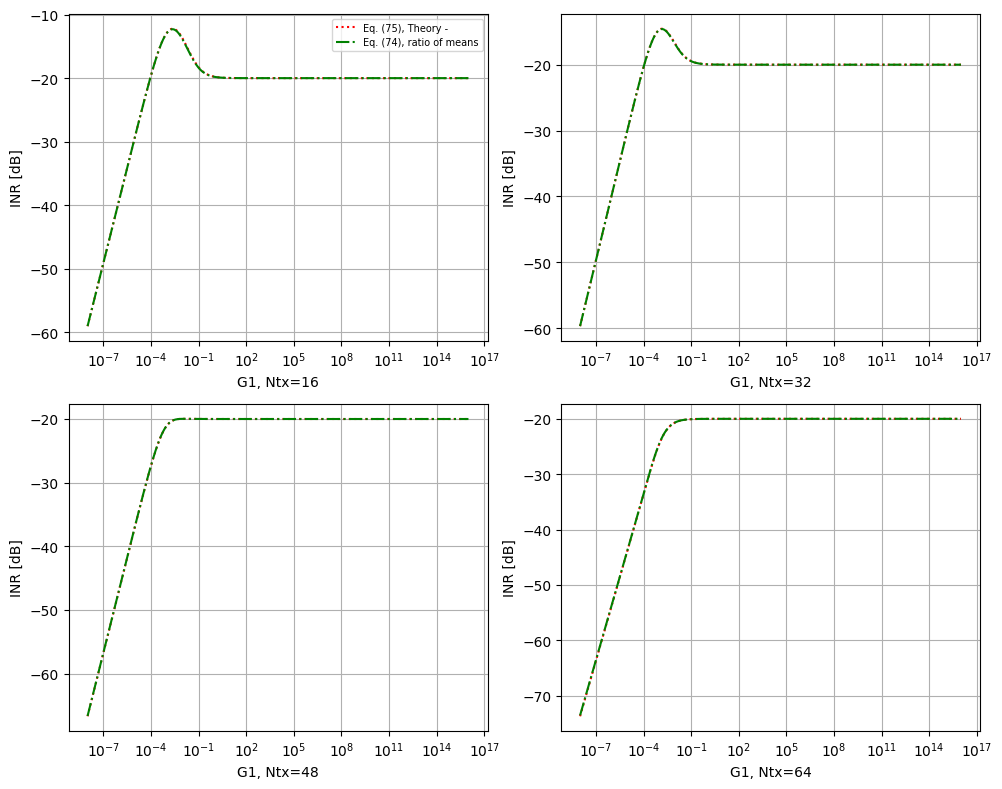

In [11]:

# ---------- Plot ----------
# Eq. (74): finite-N ratio-of-means approximation (not a guaranteed bound).
# Evaluate from the existing simulation setup; rerunning only this plot cell is sufficient.
INR_theory_ratio = np.zeros_like(INR_theory_incorrect)
plt.figure(figsize=(10, 8))

for idx, ntx in enumerate(ntx_num):

    mean_G_i = G_i[idx, :]
    gamma_r = E_r * mean_G_i / sigma_N1  # Training SNR, not channel amplitude.
    rho2 = rho_nom_abs2[idx]  # r = |rho|^2; N = ntx; k = E_t / E_r.
    INR_theory_ratio[idx, :] = (
        (E_t / E_r) * gamma_r
        * (rho2 * (ntx - 1) + (1 - rho2) * (gamma_r + 1 / ntx))
        / ((1 + gamma_r) * (1 - 1 / ntx + gamma_r * (1 - rho2)))
    )
    mean_INR_ratio = 10 * np.log10(INR_theory_ratio[idx, :])
    mean_INR_sim = 10 * np.log10(np.mean(inr[idx, :, :], axis=0))
    mean_INR_corr = 10 * np.log10(INR_theory_correct[idx, :])
    mean_INR_incorr = 10 * np.log10(INR_theory_incorrect[idx, :])
    mean_INR_SDV = 10 * np.log10(INR_from_SDV[idx, :])

    plt.subplot(2, 2, idx + 1)
    # plt.semilogx(mean_G_i, mean_INR_sim, 'k', label='MC')
    # plt.semilogx(mean_G_i, mean_INR_corr, 'b--', label='Theory +')
    plt.semilogx(mean_G_i, mean_INR_incorr, 'r:', label='Eq. (75), Theory -')
    plt.semilogx(mean_G_i, mean_INR_ratio, 'g-.', label='Eq. (74), ratio of means')
    # plt.semilogx(mean_G_i, mean_INR_SDV, 'g-.', label='S(D+V)')

    plt.xlabel(f'G1, Ntx={ntx}')
    plt.ylabel('INR [dB]')
    plt.grid(True)

    if idx == 0:
        plt.legend(fontsize=7)

plt.tight_layout()
plt.show()


In [5]:
emp_var = np.mean(np.abs(v1)**2)
theory_var = sigma_N1 / E_r
print(emp_var )
print(theory_var)

0.0009403482642450865
0.001


In [6]:
v1.shape

(64, 1)

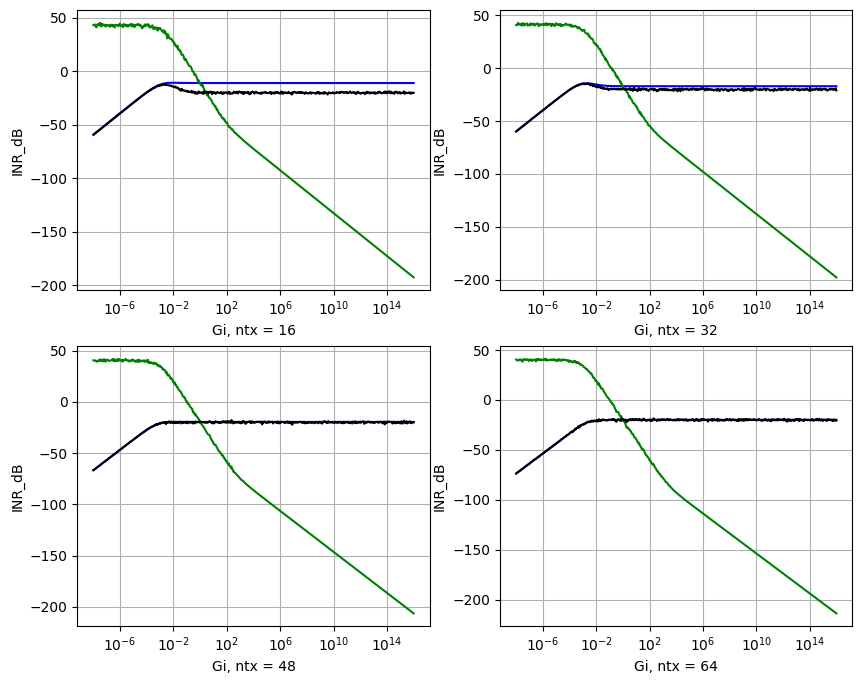

In [7]:
# Legacy diagnostics: read only the results from the first cell.
plt.figure(figsize=(10, 8))
for n, ntx in enumerate(legacy_results["ntx_num"]):

    mean_G_i = np.mean(legacy_results["G_i"][n,:,:], axis=0)
    mean_INR_theory_correct = 10*np.log10(np.mean(legacy_results["INR_theory_correct"][n,:,:], axis=0))
    mean_INR_theory_incorrect = 10*np.log10(np.mean(legacy_results["INR_theory_incorrect"][n,:,:], axis=0))
    mean_INR_pow = 10*np.log10(np.mean(legacy_results["INR_pow"][n,:,:], axis=0))
    mean_INR0_pow = 10*np.log10(np.mean(legacy_results["INR0_pow"][n,:,:], axis=0))
    mean_INR2_pow = 10*np.log10(np.mean(legacy_results["INR2_pow"][n,:,:], axis=0))
    mean_INR3_pow = 10*np.log10(np.mean(legacy_results["INR3_pow"][n,:,:], axis=0))
    mean_INR4_pow = 10*np.log10(np.mean(legacy_results["INR4_pow"][n,:,:], axis=0))
    mean_INR5_pow = 10*np.log10(np.mean(legacy_results["INR5_pow"][n,:,:], axis=0))
    mean_INR = 10*np.log10(np.mean(legacy_results["inr"][n,:,:], axis=0))
    mean_INR_new = 10*np.log10(np.mean(legacy_results["INR_new"][n,:,:], axis=0))



    plt.subplot(2,2,n+1)
    plt.semilogx(mean_G_i, mean_INR_theory_correct, color='blue', label='INR_theory_correct')
    # plt.semilogx(mean_G_i, mean_INR_theory_incorrect, color='red', label='INR_theory_incorrect')
    plt.semilogx(mean_G_i, mean_INR3_pow, color='green', label='INR_pow')
    # plt.semilogx(mean_G_i, mean_INR2_pow, color='red', label='INR_pow')
    plt.semilogx(mean_G_i, mean_INR, color='black', label='INR_pow')
    plt.xlabel(f'Gi, ntx = {ntx}')
    plt.ylabel('INR_dB')
    plt.grid()
plt.show()

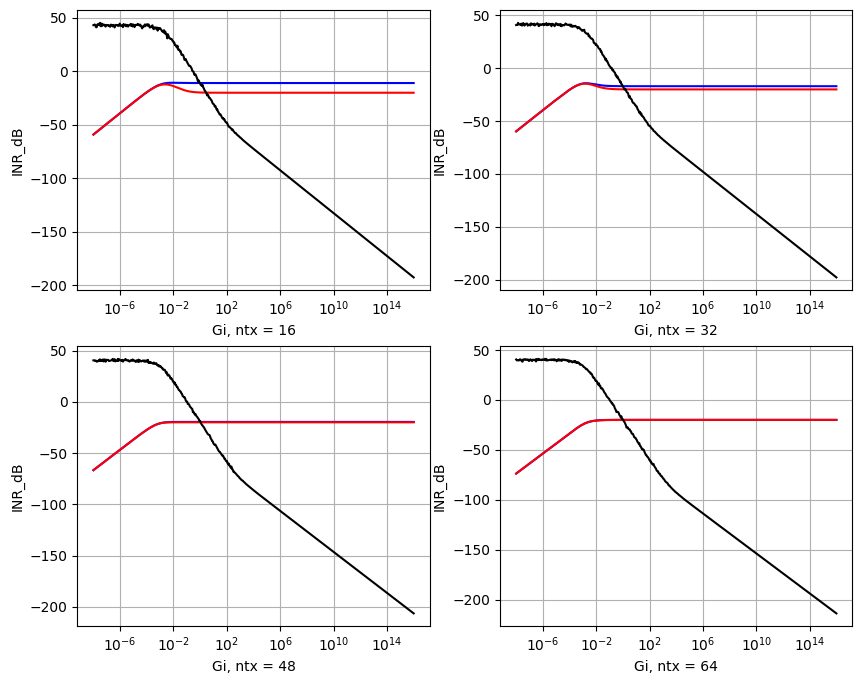

In [8]:
# Legacy diagnostics: read only the results from the first cell.
plt.figure(figsize=(10, 8))
for n, ntx in enumerate(legacy_results["ntx_num"]):

    mean_G_i = np.mean(legacy_results["G_i"][n,:,:], axis=0)
    mean_INR_theory_correct = 10*np.log10(np.mean(legacy_results["INR_theory_correct"][n,:,:], axis=0))
    mean_INR_theory_incorrect = 10*np.log10(np.mean(legacy_results["INR_theory_incorrect"][n,:,:], axis=0))
    mean_INR_pow = 10*np.log10(np.mean(legacy_results["INR_pow"][n,:,:], axis=0))
    mean_INR0_pow = 10*np.log10(np.mean(legacy_results["INR0_pow"][n,:,:], axis=0))
    mean_INR2_pow = 10*np.log10(np.mean(legacy_results["INR2_pow"][n,:,:], axis=0))
    mean_INR3_pow = 10*np.log10(np.mean(legacy_results["INR3_pow"][n,:,:], axis=0))
    mean_INR = 10*np.log10(np.mean(legacy_results["inr"][n,:,:], axis=0))
    mean_INR_new = 10*np.log10(np.mean(legacy_results["INR_new"][n,:,:], axis=0))



    plt.subplot(2,2,n+1)
    plt.semilogx(mean_G_i, mean_INR_theory_correct, color='blue', label='INR_theory_correct')
    plt.semilogx(mean_G_i, mean_INR_theory_incorrect, color='red', label='INR_theory_incorrect')
    # plt.semilogx(mean_G_i, mean_INR_pow, color='green', label='INR_pow')
    plt.semilogx(mean_G_i, mean_INR3_pow, color='black', label='INR_pow')
    plt.xlabel(f'Gi, ntx = {ntx}')
    plt.ylabel('INR_dB')
    plt.grid()
plt.show()

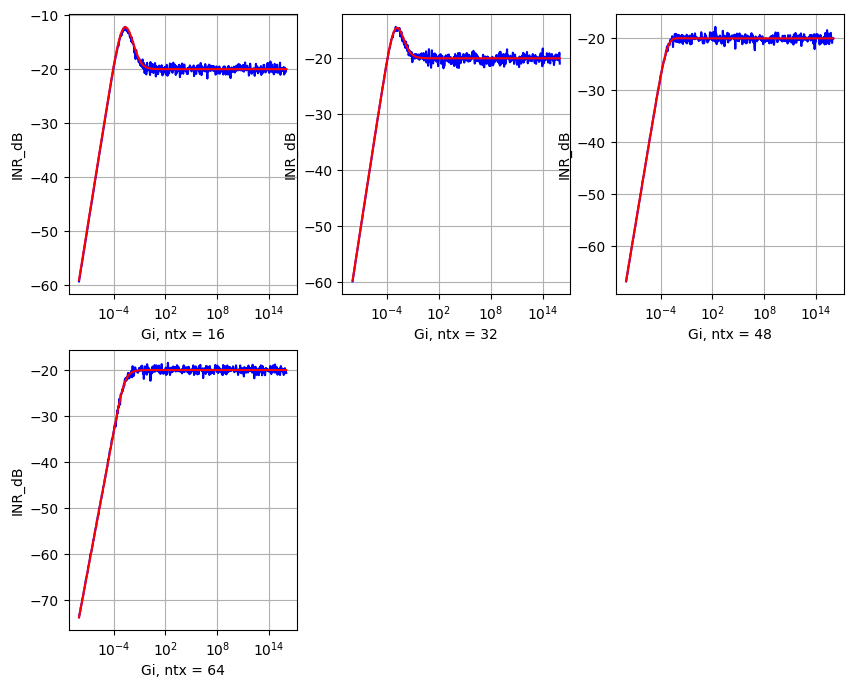

In [9]:
# Legacy diagnostics: read only the results from the first cell.
plt.figure(figsize=(10, 8))
for n, ntx in enumerate(legacy_results["ntx_num"]):

    mean_G_i = np.mean(legacy_results["G_i"][n,:,:], axis=0)
    mean_INR_theory_correct = 10*np.log10(np.mean(legacy_results["INR_theory_correct"][n,:,:], axis=0))
    mean_INR_theory_incorrect = 10*np.log10(np.mean(legacy_results["INR_theory_incorrect"][n,:,:], axis=0))
    mean_INR_pow = 10*np.log10(np.mean(legacy_results["INR_pow"][n,:,:], axis=0))
    mean_INR = 10*np.log10(np.mean(legacy_results["inr"][n,:,:], axis=0))



    plt.subplot(2,3,n+1)
    plt.semilogx(mean_G_i, mean_INR, color='blue', label='mean_INR')
    plt.semilogx(mean_G_i, mean_INR_theory_incorrect, color='red', label='INR_theory_incorrect')
    # plt.semilogx(mean_G_i, mean_INR_pow, color='green', label='INR_pow')
    #plt.semilogx(mean_G_i, mean_INR, color='black', label='INR_pow')
    plt.xlabel(f'Gi, ntx = {ntx}')
    plt.ylabel('INR_dB')
    plt.grid()
plt.show()

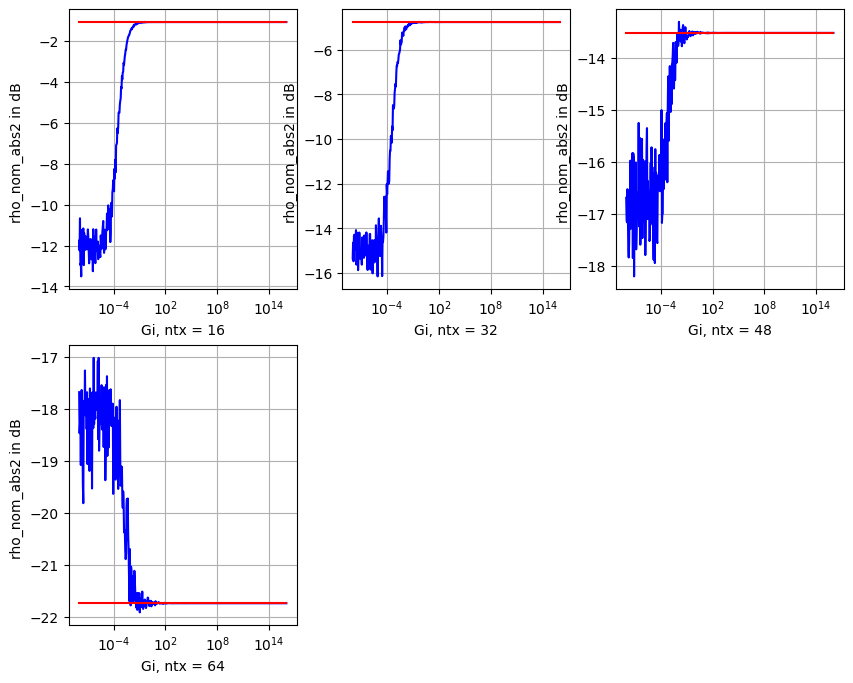

In [10]:
# Legacy diagnostics: read only the results from the first cell.
plt.figure(figsize=(10, 8))
for n, ntx in enumerate(legacy_results["ntx_num"]):

    mean_G_i = np.mean(legacy_results["G_i"][n,:,:], axis=0)
    mean_rho_hat_list= 10*np.log10(np.mean(legacy_results["rho_hat_list"][n,:,:], axis=0))
    mean_rho_nom_abs2_list = 10*np.log10(np.mean(legacy_results["rho_nom_abs2_list"][n,:,:], axis=0))



    plt.subplot(2,3,n+1)
    plt.semilogx(mean_G_i, mean_rho_hat_list, color='blue', label='Original h1 pow')
    plt.semilogx(mean_G_i, mean_rho_nom_abs2_list, color='red', label='Equalized h1 pow')
    plt.xlabel(f'Gi, ntx = {ntx}')
    plt.ylabel('rho_nom_abs2 in dB ')
    plt.grid()
plt.show()